# Load dataset

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
train = pd.read_csv("train.csv")
holidays = pd.read_csv("holidays_events.csv")
stores = pd.read_csv("stores.csv")
transactions = pd.read_csv("transactions.csv")

# Check the main dataset
train.head()

,id,date,store_nbr,family,sales,onpromotion
0,0,2013-01-01,1.0,AUTOMOTIVE,0.0,0.0
1,1,2013-01-01,1.0,BABY CARE,0.0,0.0
2,2,2013-01-01,1.0,BEAUTY,0.0,0.0
3,3,2013-01-01,1.0,BEVERAGES,0.0,0.0
4,4,2013-01-01,1.0,BOOKS,0.0,0.0


#Data Cleaning

In [2]:
print("Dataset shape:", train.shape)
print("\nColumn information:")
train.info()

print("\nMissing values:")
print(train.isnull().sum())

Dataset shape: (188350, 6)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 188350 entries, 0 to 188349
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   id           188350 non-null  int64  
 1   date         188350 non-null  object 
 2   store_nbr    188349 non-null  float64
 3   family       188349 non-null  object 
 4   sales        188349 non-null  float64
 5   onpromotion  188349 non-null  float64
dtypes: float64(3), int64(1), object(2)
memory usage: 8.6+ MB

Missing values:
id             0
date           0
store_nbr      1
family         1
sales          1
onpromotion    1
dtype: int64


In [3]:
train['date'] = pd.to_datetime(train['date'])

# Verify the conversion
print(train.dtypes)

id                      int64
date           datetime64[ns]
store_nbr             float64
family                 object
sales                 float64
onpromotion           float64
dtype: object


In [4]:
print("Start date:", train['date'].min())
print("End date:", train['date'].max())

print("Number of unique dates:", train['date'].nunique())

Start date: 2013-01-01 00:00:00
End date: 2013-04-16 00:00:00
Number of unique dates: 106


In [5]:
# Check for duplication
print("Fully duplicated rows:", train.duplicated().sum())

print(
    "Duplicated store-family-date combinations:",
    train.duplicated(
        subset=['date', 'store_nbr', 'family']
    ).sum()
)

Fully duplicated rows: 0
Duplicated store-family-date combinations: 0


In [6]:
# Check for missing dates

full_dates = pd.date_range(
    start=train['date'].min(),
    end=train['date'].max(),
    freq='D'
)

missing_dates = full_dates.difference(
    train['date'].unique()
)

print("Expected days:", len(full_dates))
print("Actual unique days:", train['date'].nunique())
print("Missing days:", len(missing_dates))
print(missing_dates)

Expected days: 106
Actual unique days: 106
Missing days: 0
DatetimeIndex([], dtype='datetime64[ns]', freq='D')


In [7]:
# Aggregate daily sales

daily_sales = (
    train.groupby('date', as_index=False)['sales']
    .sum()
    .rename(columns={
        'date': 'ds',
        'sales': 'y'
    })
    .sort_values('ds')
)

print(daily_sales.shape)
display(daily_sales.head())

(106, 2)


,ds,y
0,2013-01-01,2511.618999
1,2013-01-02,496092.417944
2,2013-01-03,361461.231124
3,2013-01-04,354459.677093
4,2013-01-05,477350.121229


#Explortory Data Analysis

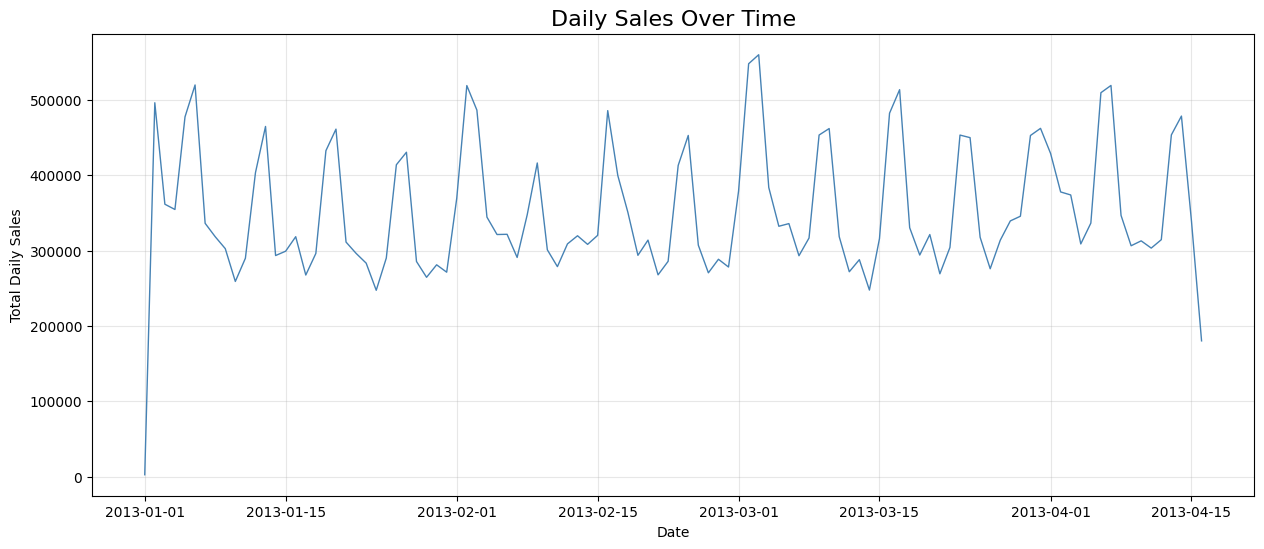

In [8]:
# Visualize daily sales over time
plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales['ds'],
    daily_sales['y'],
    color='steelblue',
    linewidth=1
)

plt.title('Daily Sales Over Time', fontsize=16)
plt.xlabel('Date')
plt.ylabel('Total Daily Sales')
plt.grid(alpha=0.3)

plt.show()

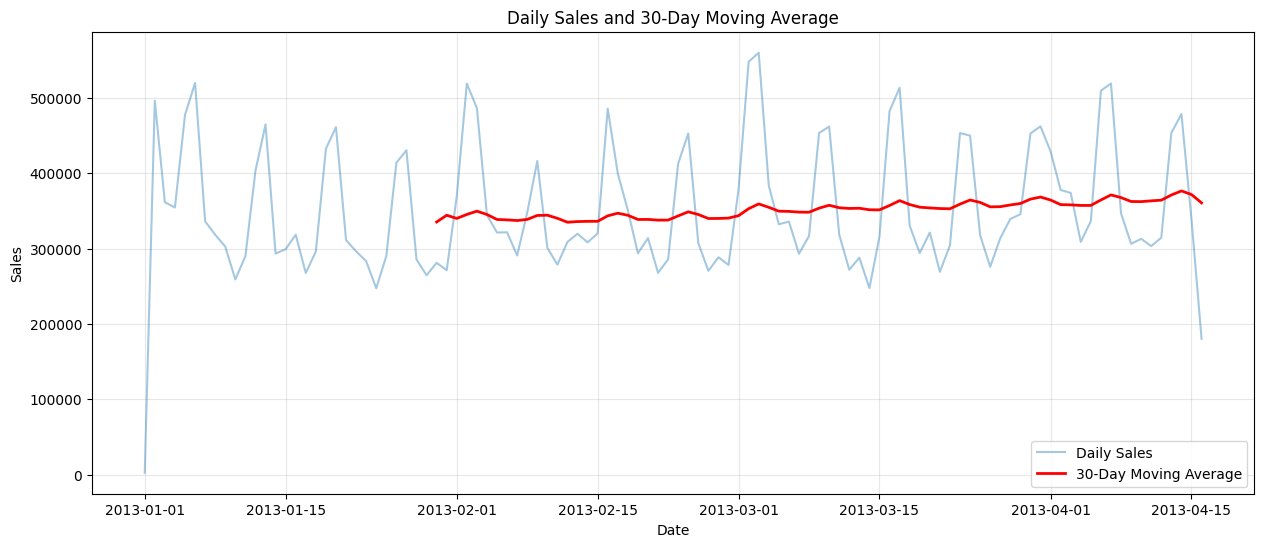

In [9]:
# Visualize the trend using a 30-day moving average

daily_sales['MA_30'] = (
    daily_sales['y']
    .rolling(window=30)
    .mean()
)

plt.figure(figsize=(15, 6))

plt.plot(
    daily_sales['ds'],
    daily_sales['y'],
    label='Daily Sales',
    alpha=0.4
)

plt.plot(
    daily_sales['ds'],
    daily_sales['MA_30'],
    label='30-Day Moving Average',
    color='red',
    linewidth=2
)

plt.title('Daily Sales and 30-Day Moving Average')
plt.xlabel('Date')
plt.ylabel('Sales')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

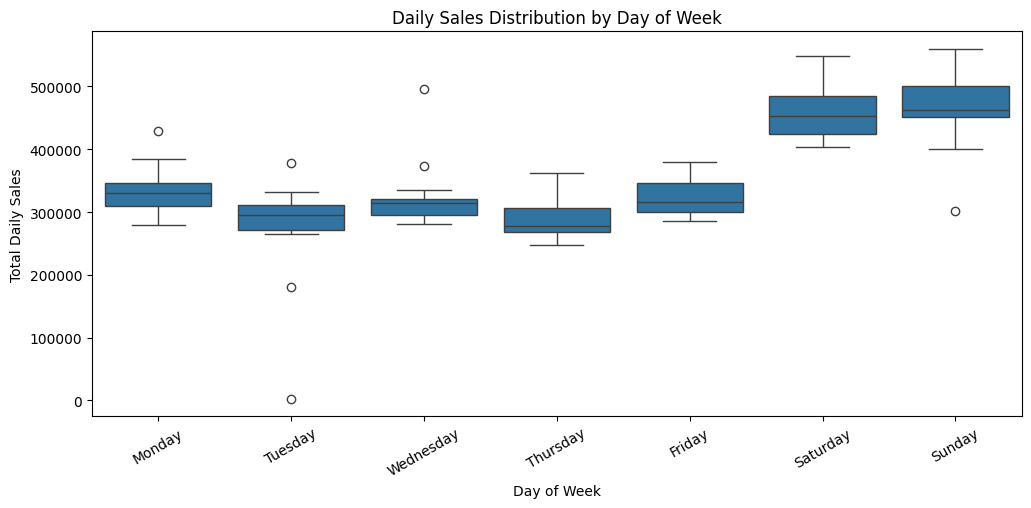

In [10]:
# Analyze weekly seasonality
daily_sales['day_of_week'] = daily_sales['ds'].dt.day_name()

week_order = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=daily_sales,
    x='day_of_week',
    y='y',
    order=week_order
)

plt.title('Daily Sales Distribution by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Total Daily Sales')
plt.xticks(rotation=30)

plt.show()

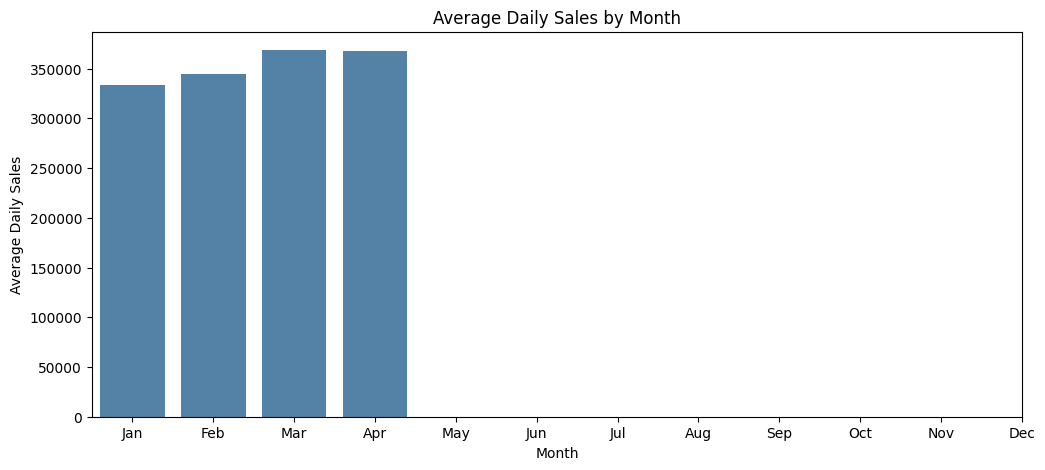

In [11]:
#Monthly and Yearly Seasonality
daily_sales['month'] = daily_sales['ds'].dt.month

monthly_sales = (
    daily_sales.groupby('month')['y']
    .mean()
)

plt.figure(figsize=(12, 5))

sns.barplot(
    x=monthly_sales.index,
    y=monthly_sales.values,
    color='steelblue'
)

plt.title('Average Daily Sales by Month')
plt.xlabel('Month')
plt.ylabel('Average Daily Sales')
plt.xticks(
    range(12),
    ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
     'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
)

plt.show()

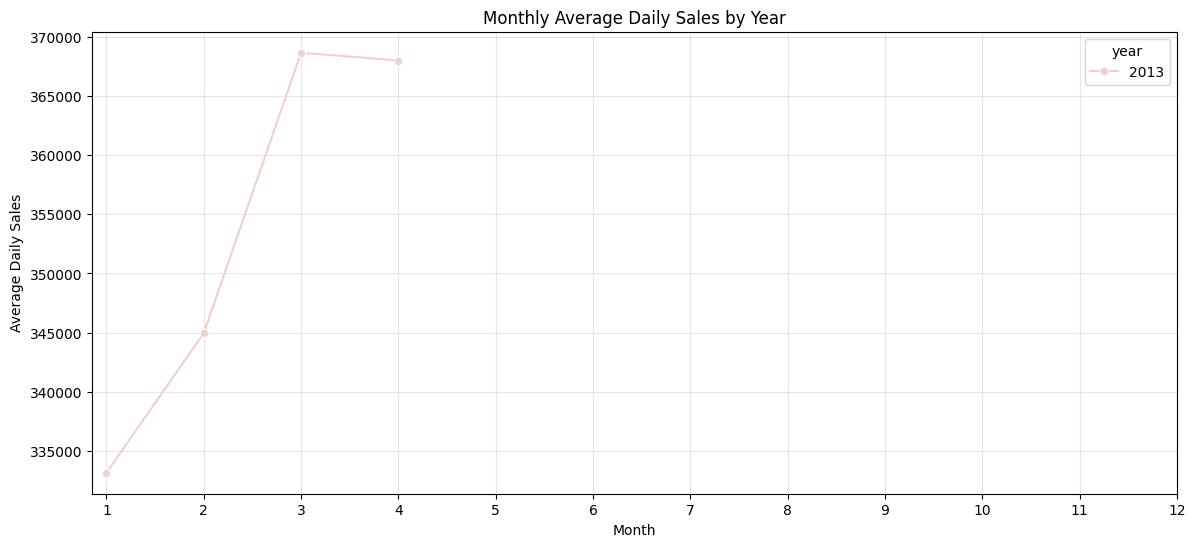

In [12]:
#Compare sales across years
daily_sales['year'] = daily_sales['ds'].dt.year

plt.figure(figsize=(14, 6))

sns.lineplot(
    data=daily_sales,
    x='month',
    y='y',
    hue='year',
    estimator='mean',
    errorbar=None,
    marker='o'
)

plt.title('Monthly Average Daily Sales by Year')
plt.xlabel('Month')
plt.ylabel('Average Daily Sales')
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)

plt.show()

In [13]:
#Investigate unusually low sales
lowest_sales = daily_sales.nsmallest(
    15, 'y'
)[['ds', 'y']]

display(lowest_sales)

,ds,y
0,2013-01-01,2511.618999
105,2013-04-16,180127.449019
23,2013-01-24,247245.690995
72,2013-03-14,247541.420096
9,2013-01-10,258982.003049
28,2013-01-29,264488.818076
16,2013-01-17,267498.515975
51,2013-02-21,267711.109015
79,2013-03-21,269130.127953
56,2013-02-26,270425.007067


#Investigating Holiday Effects

In [14]:
holidays.head(10)

,date,type,locale,locale_name,description,transferred
0,2012-03-02,Holiday,Local,Manta,Fundacion de Manta,False
1,2012-04-01,Holiday,Regional,Cotopaxi,Provincializacion de Cotopaxi,False
2,2012-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,False
3,2012-04-14,Holiday,Local,Libertad,Cantonizacion de Libertad,False
4,2012-04-21,Holiday,Local,Riobamba,Cantonizacion de Riobamba,False
5,2012-05-12,Holiday,Local,Puyo,Cantonizacion del Puyo,False
6,2012-06-23,Holiday,Local,Guaranda,Cantonizacion de Guaranda,False
7,2012-06-25,Holiday,Regional,Imbabura,Provincializacion de Imbabura,False
8,2012-06-25,Holiday,Local,Latacunga,Cantonizacion de Latacunga,False
9,2012-06-25,Holiday,Local,Machala,Fundacion de Machala,False


In [15]:
holidays.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 350 entries, 0 to 349
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   date         350 non-null    object
 1   type         350 non-null    object
 2   locale       350 non-null    object
 3   locale_name  350 non-null    object
 4   description  350 non-null    object
 5   transferred  350 non-null    bool  
dtypes: bool(1), object(5)
memory usage: 14.1+ KB


In [16]:
#Examine New Year's Day
holidays['date'] = pd.to_datetime(holidays['date'])

new_year_holidays = holidays[
    (holidays['date'].dt.month == 1) &
    (holidays['date'].dt.day == 1)
]

display(new_year_holidays)

#Check holiday type

print(holidays['type'].value_counts())

,date,type,locale,locale_name,description,transferred
41,2013-01-01,Holiday,National,Ecuador,Primer dia del ano,False
92,2014-01-01,Holiday,National,Ecuador,Primer dia del ano,False
159,2015-01-01,Holiday,National,Ecuador,Primer dia del ano,False
211,2016-01-01,Holiday,National,Ecuador,Primer dia del ano,False
297,2017-01-01,Holiday,National,Ecuador,Primer dia del ano,True


type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64


In [17]:
#Check the final training date
display(
    train[
        train['date'].between(
            '2017-01-23',
            '2017-01-26'
        )
    ]
    .groupby('date')['sales']
    .agg(['sum', 'count'])
)

,sum,count
date,,


In [18]:
print(train['date'].dtype)

print("Minimum date:", train['date'].min())
print("Maximum date:", train['date'].max())

print(train['date'].tail())

datetime64[ns]
Minimum date: 2013-01-01 00:00:00
Maximum date: 2013-04-16 00:00:00
188345   2013-04-16
188346   2013-04-16
188347   2013-04-16
188348   2013-04-16
188349   2013-04-16
Name: date, dtype: datetime64[ns]


In [19]:
print("Current dataset shape:", train.shape)
print("Maximum date:", train['date'].max())

Current dataset shape: (188350, 6)
Maximum date: 2013-04-16 00:00:00


In [20]:
train = pd.read_csv("train.csv")

train['date'] = pd.to_datetime(train['date'])

print("Dataset shape:", train.shape)
print("Maximum date:", train['date'].max())

Dataset shape: (294285, 6)
Maximum date: 2013-06-15 00:00:00


In [21]:
final_dates = train[
    train['date'].between(
        '2017-01-23',
        '2017-01-26'
    )
]

display(
    final_dates.groupby('date')['sales']
    .agg(['sum', 'count'])
)

,sum,count
date,,


In [22]:
daily_sales = (
    train.groupby('date', as_index=False)['sales']
    .sum()
    .rename(columns={
        'date': 'ds',
        'sales': 'y'
    })
    .sort_values('ds')
)

print(daily_sales.shape)

(166, 2)


In [23]:
print("Dataset shape:", train.shape)

print("Start date:", train['date'].min())
print("End date:", train['date'].max())

print("Unique dates:", train['date'].nunique())

print("Duplicate rows:", train.duplicated().sum())

print(
    "Duplicate date-store-family records:",
    train.duplicated(
        subset=['date', 'store_nbr', 'family']
    ).sum()
)

Dataset shape: (294285, 6)
Start date: 2013-01-01 00:00:00
End date: 2013-06-15 00:00:00
Unique dates: 166
Duplicate rows: 0
Duplicate date-store-family records: 0


In [24]:
last_days = (
    train.groupby('date')
    .agg(
        total_sales=('sales', 'sum'),
        records=('sales', 'size')
    )
    .tail(10)
)

display(last_days)

,total_sales,records
date,,
2013-06-06,317496.765891,1782
2013-06-07,357673.087977,1782
2013-06-08,466292.699096,1782
2013-06-09,526804.730256,1782
2013-06-10,349754.291978,1782
2013-06-11,283858.215993,1782
2013-06-12,320173.577999,1782
2013-06-13,282886.920045,1782
2013-06-14,326956.742107,1782


#Train and Test split

In [25]:
daily_sales = (
    train.groupby('date', as_index=False)['sales']
    .sum()
    .rename(columns={'date': 'ds', 'sales': 'y'})
    .sort_values('ds')
    .reset_index(drop=True)
)

In [26]:
# Last 90 calendar days for testing
test_start = daily_sales['ds'].max() - pd.Timedelta(days=89)

train_data = daily_sales[
    daily_sales['ds'] < test_start
].copy()

test_data = daily_sales[
    daily_sales['ds'] >= test_start
].copy()

print("Training shape:", train_data.shape)
print("Testing shape:", test_data.shape)

print("Training period:",
      train_data['ds'].min(),
      "to", train_data['ds'].max())

print("Testing period:",
      test_data['ds'].min(),
      "to", test_data['ds'].max())

Training shape: (76, 2)
Testing shape: (90, 2)
Training period: 2013-01-01 00:00:00 to 2013-03-17 00:00:00
Testing period: 2013-03-18 00:00:00 to 2013-06-15 00:00:00


#Visuilize the split

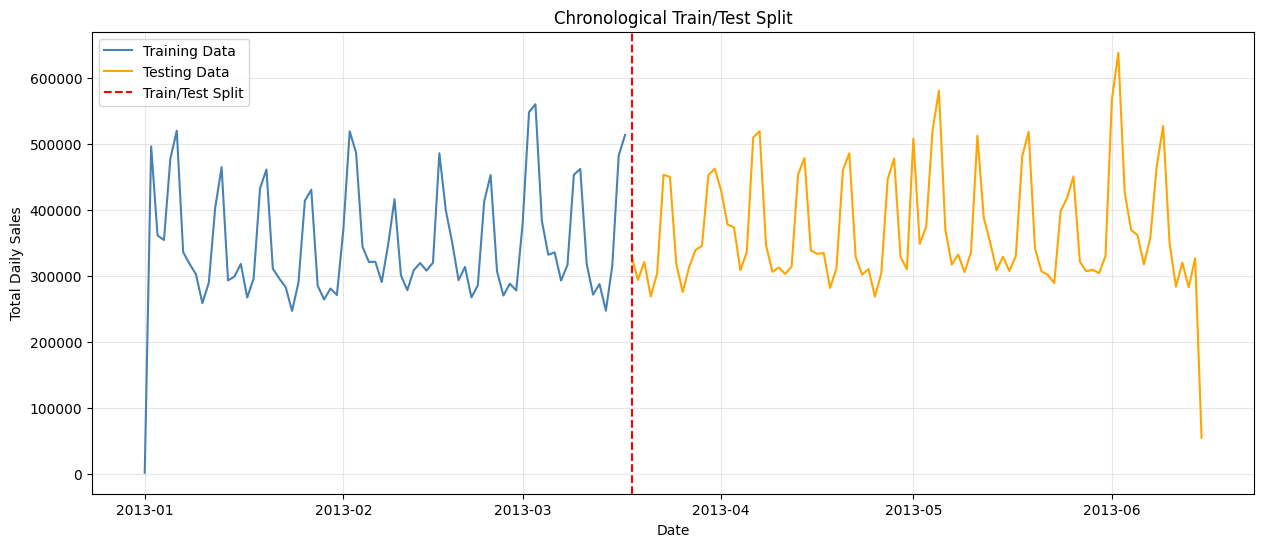

In [27]:
plt.figure(figsize=(15, 6))

plt.plot(
    train_data['ds'],
    train_data['y'],
    label='Training Data',
    color='steelblue'
)

plt.plot(
    test_data['ds'],
    test_data['y'],
    label='Testing Data',
    color='orange'
)

plt.axvline(
    test_start,
    color='red',
    linestyle='--',
    label='Train/Test Split'
)

plt.title('Chronological Train/Test Split')
plt.xlabel('Date')
plt.ylabel('Total Daily Sales')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

#Build a Baseline Forecasting Model

In [28]:
#Create the seasonal naïve forecast
train_data = train_data.sort_values('ds').copy()
test_data = test_data.sort_values('ds').copy()

last_7_days = train_data.tail(7)

display(last_7_days)

print(
    "Consecutive dates:",
    last_7_days['ds'].diff().dropna().eq(
        pd.Timedelta(days=1)
    ).all()
)

,ds,y
69,2013-03-11,318379.133021
70,2013-03-12,271823.378010
71,2013-03-13,287869.663972
72,2013-03-14,247541.420096
73,2013-03-15,315878.090213
74,2013-03-16,482233.433961
75,2013-03-17,513439.584913


Consecutive dates: True


In [29]:
import numpy as np

# Use the last 7 training observations
last_week_sales = train_data['y'].tail(7).to_numpy()

# Repeat the weekly pattern across the test horizon
baseline_predictions = np.resize(
    last_week_sales,
    len(test_data)
)

# Store predictions separately
baseline_results = test_data[['ds', 'y']].copy()

baseline_results['y_pred'] = baseline_predictions

display(baseline_results.head(10))

,ds,y,y_pred
76,2013-03-18,330283.803030,318379.133021
77,2013-03-19,294020.245897,271823.378010
78,2013-03-20,321207.006946,287869.663972
79,2013-03-21,269130.127953,247541.420096
80,2013-03-22,304100.453969,315878.090213
81,2013-03-23,453192.003086,482233.433961
82,2013-03-24,449794.636951,513439.584913
83,2013-03-25,317559.609959,318379.133021
84,2013-03-26,275818.235900,271823.378010
85,2013-03-27,313691.148998,287869.663972


In [30]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error

y_true = baseline_results['y']
y_pred = baseline_results['y_pred']

mae = mean_absolute_error(y_true, y_pred)

rmse = np.sqrt(
    mean_squared_error(y_true, y_pred)
)

wape = (
    np.abs(y_true - y_pred).sum()
    / np.abs(y_true).sum()
) * 100

print(f"Baseline MAE: {mae:,.2f}")
print(f"Baseline RMSE: {rmse:,.2f}")
print(f"Baseline WAPE: {wape:.2f}%")

Baseline MAE: 46,338.35
Baseline RMSE: 70,585.91
Baseline WAPE: 12.57%


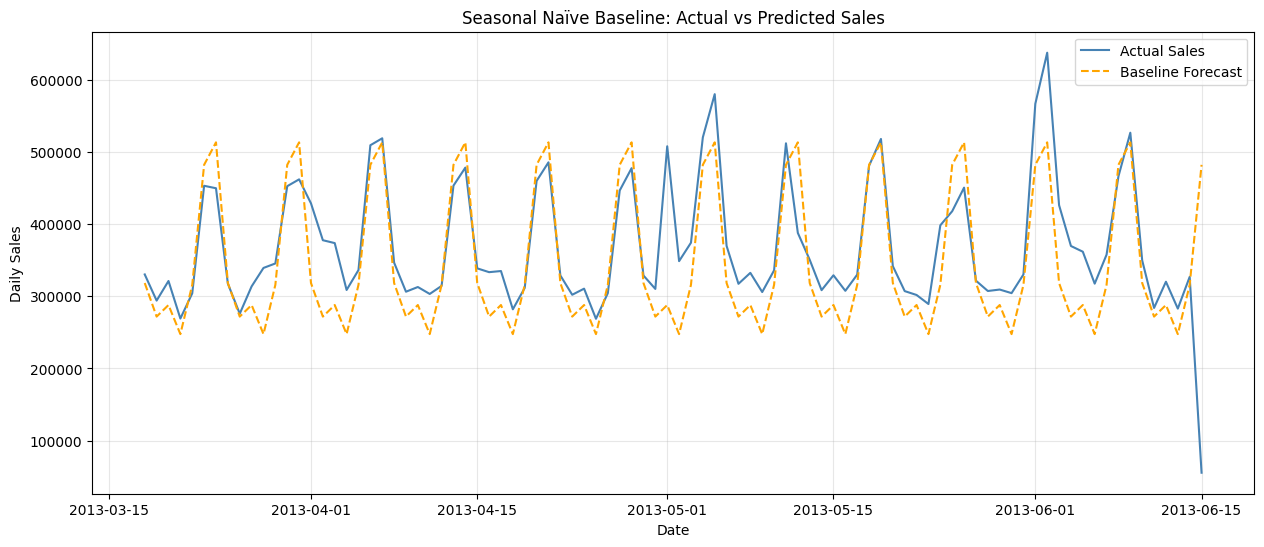

In [31]:
plt.figure(figsize=(15, 6))

plt.plot(
    baseline_results['ds'],
    baseline_results['y'],
    label='Actual Sales',
    color='steelblue'
)

plt.plot(
    baseline_results['ds'],
    baseline_results['y_pred'],
    label='Baseline Forecast',
    color='orange',
    linestyle='--'
)

plt.title('Seasonal Naïve Baseline: Actual vs Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Daily Sales')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [32]:
baseline_metrics = {
    'Model': 'Seasonal Naive',
    'MAE': mae,
    'RMSE': rmse,
    'WAPE': wape
}

baseline_metrics

{'Model': 'Seasonal Naive',
 'MAE': 46338.34907471222,
 'RMSE': np.float64(70585.9119840319),
 'WAPE': np.float64(12.573258536433324)}

#Train Our First Facebook Prophet Model

In [ ]:
!pip install prophet

In [ ]:
from prophet import Prophet
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)
prophet_model.fit(
    train_data[['ds', 'y']]
)

#Generate predictions

future = test_data[['ds']].copy()

forecast = prophet_model.predict(future)

display(
    forecast[
        ['ds', 'yhat', 'yhat_lower', 'yhat_upper']
    ].head()
)

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    test_data['ds'],
    test_data['y'],
    label='Actual Sales',
    color='steelblue'
)

plt.plot(
    forecast['ds'],
    forecast['yhat'],
    label='Prophet Forecast',
    color='red'
)

plt.fill_between(
    forecast['ds'],
    forecast['yhat_lower'],
    forecast['yhat_upper'],
    color='red',
    alpha=0.15,
    label='Uncertainty Interval'
)

plt.title('Facebook Prophet: Actual vs Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Daily Sales')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
#Evaluate

from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = test_data['y'].to_numpy()
predicted = forecast['yhat'].to_numpy()

prophet_mae = mean_absolute_error(actual, predicted)

prophet_rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

prophet_wape = (
    np.abs(actual - predicted).sum()
    / np.abs(actual).sum()
) * 100

print(f"Prophet MAE: {prophet_mae:,.2f}")
print(f"Prophet RMSE: {prophet_rmse:,.2f}")
print(f"Prophet WAPE: {prophet_wape:.2f}%")

#Compare the two models

In [ ]:
comparison = pd.DataFrame([
    baseline_metrics,
    {
        'Model': 'Facebook Prophet',
        'MAE': prophet_mae,
        'RMSE': prophet_rmse,
        'WAPE': prophet_wape
    }
])

display(comparison)

#Interpret Prophet's Components

In [ ]:
fig = prophet_model.plot_components(forecast)

plt.show()

# Generate a historical component analysis

In [ ]:
historical_forecast = prophet_model.predict(
    train_data[['ds']]
)

fig = prophet_model.plot_components(
    historical_forecast
)

plt.show()

#Prepare to Improve Prophet with Holidays

In [ ]:
national_holidays = holidays[
    holidays['locale'] == 'National'
].copy()

print(
    national_holidays['type'].value_counts()
)

display(
    national_holidays[
        ['date', 'type', 'description', 'transferred']
    ].head(20)
)

In [ ]:
display(
    national_holidays[
        national_holidays['transferred'] == True
    ][['date', 'type', 'description', 'transferred']]
    .head(15)
)

#Create the Prophet holiday DataFrame

In [ ]:
# Select national holidays
national_holidays = holidays[
    holidays['locale'] == 'National'
].copy()

# Keep observed national holidays
prophet_holidays = national_holidays[
    (
        (national_holidays['type'] == 'Holiday') &
        (national_holidays['transferred'] == False)
    )
    |
    (national_holidays['type'] == 'Transfer')
].copy()

# Prepare the format required by Prophet
prophet_holidays = prophet_holidays.rename(
    columns={
        'date': 'ds',
        'description': 'holiday'
    }
)

prophet_holidays = prophet_holidays[
    ['ds', 'holiday']
].drop_duplicates()

prophet_holidays['ds'] = pd.to_datetime(
    prophet_holidays['ds']
)

display(prophet_holidays.head(10))

print(
    "Total holiday records:",
    len(prophet_holidays)
)

In [ ]:
new_year_events = holidays[
    (
        (holidays['date'].dt.month == 1) &
        (holidays['date'].dt.day <= 3)
    )
    &
    (holidays['locale'] == 'National')
]

display(
    new_year_events[
        ['date', 'type', 'description', 'transferred']
    ].sort_values('date')
)

In [ ]:
prophet_v2 = Prophet(
    holidays=prophet_holidays,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

In [ ]:
# Create New Year's Day events
new_year_dates = pd.date_range(
    start='2013-01-01',
    end='2017-12-31',
    freq='YS'
)

new_year_effect = pd.DataFrame({
    'ds': new_year_dates,
    'holiday': 'New_Years_Day'
})

# Remove existing January 1 records
# to avoid overlapping holiday definitions
prophet_holidays = prophet_holidays[
    ~(
        (prophet_holidays['ds'].dt.month == 1) &
        (prophet_holidays['ds'].dt.day == 1)
    )
].copy()

# Add the recurring event
prophet_holidays = pd.concat(
    [prophet_holidays, new_year_effect],
    ignore_index=True
)

prophet_holidays = (
    prophet_holidays
    .drop_duplicates()
    .sort_values('ds')
    .reset_index(drop=True)
)

display(prophet_holidays.tail(10))

#Train Prophet Version 2

In [ ]:
prophet_v2 = Prophet(
    holidays=prophet_holidays,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

prophet_v2.fit(
    train_data[['ds', 'y']]
)

In [ ]:
#Generate prediction
forecast_v2 = prophet_v2.predict(
    test_data[['ds']]
)

display(
    forecast_v2[
        ['ds', 'yhat', 'yhat_lower', 'yhat_upper']
    ].head()
)

In [ ]:
plt.figure(figsize=(15, 6))

plt.plot(
    test_data['ds'],
    test_data['y'],
    label='Actual Sales',
    color='steelblue'
)

plt.plot(
    forecast_v2['ds'],
    forecast_v2['yhat'],
    label='Prophet V2 Forecast',
    color='red'
)

plt.fill_between(
    forecast_v2['ds'],
    forecast_v2['yhat_lower'],
    forecast_v2['yhat_upper'],
    alpha=0.2,
    color='red',
    label='Uncertainty Interval'
)

plt.title('Prophet V2: Actual vs Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Total Daily Sales')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
#Evaluate

from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = test_data['y'].to_numpy()
predicted_v2 = forecast_v2['yhat'].to_numpy()

v2_mae = mean_absolute_error(actual, predicted_v2)

v2_rmse = np.sqrt(
    mean_squared_error(actual, predicted_v2)
)

v2_wape = (
    np.abs(actual - predicted_v2).sum()
    / np.abs(actual).sum()
) * 100

print(f"Prophet V2 MAE: {v2_mae:,.2f}")
print(f"Prophet V2 RMSE: {v2_rmse:,.2f}")
print(f"Prophet V2 WAPE: {v2_wape:.2f}%")

In [ ]:
#Compare the three models

comparison_v2 = pd.DataFrame([
    baseline_metrics,
    {
        'Model': 'Prophet V1',
        'MAE': prophet_mae,
        'RMSE': prophet_rmse,
        'WAPE': prophet_wape
    },
    {
        'Model': 'Prophet V2 + Holidays',
        'MAE': v2_mae,
        'RMSE': v2_rmse,
        'WAPE': v2_wape
    }
])

display(comparison_v2.round(2))

#Import Prophet's cross-validation tools

In [ ]:
from prophet.diagnostics import cross_validation, performance_metrics

cv_results = cross_validation(
    prophet_v2,
    initial='730 days',
    period='180 days',
    horizon='90 days'
)

display(cv_results.head())

cv_metrics = performance_metrics(
    cv_results,
    rolling_window=1
)

display(
    cv_metrics[
        ['horizon', 'mae', 'rmse', 'mape']
    ]
)

cv_wape = (
    (cv_results['y'] - cv_results['yhat']).abs().sum()
    / cv_results['y'].abs().sum()
) * 100

print(f"Cross-validation WAPE: {cv_wape:.2f}%")

In [ ]:
cv_wape = (
    (cv_results['y'] - cv_results['yhat']).abs().sum()
    / cv_results['y'].abs().sum()
) * 100

print(f"Cross-validation WAPE: {cv_wape:.2f}%")

#Compare Prophet V1 and V2 using cross-validation

In [ ]:
cv_results_v1 = cross_validation(
    prophet_model,
    initial='730 days',
    period='180 days',
    horizon='90 days'
)

cv_wape_v1 = (
    (cv_results_v1['y'] - cv_results_v1['yhat']).abs().sum()
    / cv_results_v1['y'].abs().sum()
) * 100

print(f"Prophet V1 CV WAPE: {cv_wape_v1:.2f}%")
print(f"Prophet V2 CV WAPE: {cv_wape:.2f}%")

#Hyperparameter Tuning

In [ ]:
import itertools
import pandas as pd

param_grid = {
    'changepoint_prior_scale': [0.01, 0.05, 0.1],
    'seasonality_prior_scale': [1.0, 10.0]
}

all_params = [
    dict(zip(param_grid.keys(), values))
    for values in itertools.product(*param_grid.values())
]

print("Total combinations:", len(all_params))

display(pd.DataFrame(all_params))

In [ ]:
from prophet import Prophet
from prophet.diagnostics import cross_validation

tuning_results = []

for params in all_params:

    model = Prophet(
        **params,
        yearly_seasonality=True,
        weekly_seasonality=True,
        daily_seasonality=False
    )

    model.fit(train_data[['ds', 'y']])

    cv = cross_validation(
        model,
        initial='730 days',
        period='180 days',
        horizon='90 days'
    )

    wape = (
        (cv['y'] - cv['yhat']).abs().sum()
        / cv['y'].abs().sum()
    ) * 100

    tuning_results.append({
        **params,
        'WAPE': wape
    })

    print(f"Parameters: {params} | CV WAPE: {wape:.2f}%")

In [ ]:
#Compare the results

tuning_df = pd.DataFrame(tuning_results)

tuning_df = tuning_df.sort_values(
    'WAPE'
).reset_index(drop=True)

display(tuning_df.round(3))

In [ ]:
#Extract the best parameters

best_params = tuning_df.iloc[0][
    ['changepoint_prior_scale',
     'seasonality_prior_scale']
].to_dict()

print("Best parameters:", best_params)
print("Best CV WAPE:", round(tuning_df.iloc[0]['WAPE'], 2))

#Train the tuned model

In [ ]:
from prophet import Prophet

prophet_tuned = Prophet(
    **best_params,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

prophet_tuned.fit(train_data[['ds', 'y']])

In [ ]:
#Generate predictions

forecast_tuned = prophet_tuned.predict(
    test_data[['ds']]
)

display(
    forecast_tuned[
        ['ds', 'yhat', 'yhat_lower', 'yhat_upper']
    ].head()
)

In [ ]:
#Evalute the tuned model

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual = test_data['y'].to_numpy()
predicted = forecast_tuned['yhat'].to_numpy()

tuned_mae = mean_absolute_error(actual, predicted)

tuned_rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

tuned_wape = (
    np.abs(actual - predicted).sum()
    / np.abs(actual).sum()
) * 100

print(f"Tuned Prophet MAE: {tuned_mae:,.2f}")
print(f"Tuned Prophet RMSE: {tuned_rmse:,.2f}")
print(f"Tuned Prophet WAPE: {tuned_wape:.2f}%")

In [ ]:
#Compare the four models

final_comparison = pd.DataFrame([
    baseline_metrics,
    {
        'Model': 'Prophet V1',
        'MAE': prophet_mae,
        'RMSE': prophet_rmse,
        'WAPE': prophet_wape
    },
    {
        'Model': 'Prophet V2 + Holidays',
        'MAE': v2_mae,
        'RMSE': v2_rmse,
        'WAPE': v2_wape
    },
    {
        'Model': 'Tuned Prophet V1',
        'MAE': tuned_mae,
        'RMSE': tuned_rmse,
        'WAPE': tuned_wape
    }
])

display(final_comparison.round(2))

In [ ]:
#Visulize the model

plt.figure(figsize=(15, 6))

plt.plot(
    test_data['ds'],
    test_data['y'],
    label='Actual Sales',
    color='steelblue'
)

plt.plot(
    forecast_tuned['ds'],
    forecast_tuned['yhat'],
    label='Tuned Prophet Forecast',
    color='green'
)

plt.fill_between(
    forecast_tuned['ds'],
    forecast_tuned['yhat_lower'],
    forecast_tuned['yhat_upper'],
    color='green',
    alpha=0.2,
    label='Uncertainty Interval'
)

plt.title('Tuned Prophet: Actual vs Predicted Sales')
plt.xlabel('Date')
plt.ylabel('Total Daily Sales')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

# Train the final model

In [ ]:
from prophet import Prophet

final_model = Prophet(
    **best_params,
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

final_model.fit(
    daily_sales[['ds', 'y']]
)

future_dates = final_model.make_future_dataframe(
    periods=90,
    freq='D'
)

future_forecast = final_model.predict(future_dates)

display(
    future_forecast[
        ['ds', 'yhat', 'yhat_lower', 'yhat_upper']
    ].tail(10)
)


last_date = daily_sales['ds'].max()

future_90_days = future_forecast[
    future_forecast['ds'] > last_date
][
    ['ds', 'yhat', 'yhat_lower', 'yhat_upper']
].copy()

print("Future forecast shape:", future_90_days.shape)

display(future_90_days.head())

In [ ]:
#Visualize our final forecast
fig = final_model.plot(
    future_forecast,
    figsize=(15, 6)
)

plt.title('Retail Sales Forecast - Next 90 Days')
plt.xlabel('Date')
plt.ylabel('Total Daily Sales')
plt.grid(alpha=0.3)

plt.show()

In [ ]:
#Create a clearer historical vs. future visualization
plt.figure(figsize=(15, 6))

# Show the last 180 days of historical sales
recent_sales = daily_sales.tail(180)

plt.plot(
    recent_sales['ds'],
    recent_sales['y'],
    label='Historical Sales',
    color='steelblue'
)

plt.plot(
    future_90_days['ds'],
    future_90_days['yhat'],
    label='Future Forecast',
    color='green'
)

plt.fill_between(
    future_90_days['ds'],
    future_90_days['yhat_lower'],
    future_90_days['yhat_upper'],
    color='green',
    alpha=0.2,
    label='Uncertainty Interval'
)

plt.axvline(
    last_date,
    color='red',
    linestyle='--',
    label='Forecast Start'
)

plt.title('90-Day Retail Sales Forecast')
plt.xlabel('Date')
plt.ylabel('Total Daily Sales')
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [ ]:
#Save the forecast
future_90_days.to_csv(
    'future_sales_forecast.csv',
    index=False
)

print("Forecast saved successfully!")

In [ ]:
daily_sales[['ds', 'y']].to_csv(
    'daily_sales.csv',
    index=False
)